# UCS420 Cognitive Computing — Lab Assignment 10
## NLP using Python-II
**Topics:** Feature extraction from text, sentiment analysis, and text generation

**How to use:** Open this notebook in Google Colab, then choose **Runtime → Run all**. If a download prompt appears for NLTK data, the setup cell below should handle it. Review the printed outputs and add your name/roll number if required by your instructor.

In [ ]:
# Q0. Install/import dependencies
%pip -q install nltk scikit-learn textblob wordcloud matplotlib tensorflow

In [ ]:
import re
import nltk
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("Libraries and NLTK resources are ready.")

Libraries and NLTK resources are ready.


Original paragraph:
 Artificial intelligence is changing how people solve everyday problems. It helps computers recognize patterns, understand language, and make useful predictions. I find AI exciting because it combines creativity with logical thinking. Responsible AI should be designed to protect privacy and reduce unfair bias. Students can use AI tools to explore ideas, but they should still verify information carefully. In the future, I hope AI will support people in education, healthcare, and scientific research.

Lowercase and punctuation removed:
 artificial intelligence is changing how people solve everyday problems it helps computers recognize patterns understand language and make useful predictions i find ai exciting because it combines creativity with logical thinking responsible ai should be designed to protect privacy and reduce unfair bias students can use ai tools to explore ideas but they should still verify information carefully in the future i hope ai will support peo

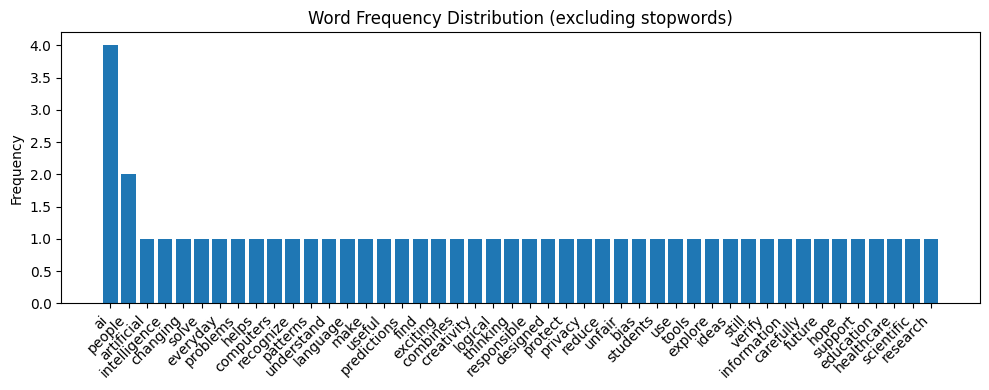

In [ ]:
paragraph = (
    "Artificial intelligence is changing how people solve everyday problems. "
    "It helps computers recognize patterns, understand language, and make useful predictions. "
    "I find AI exciting because it combines creativity with logical thinking. "
    "Responsible AI should be designed to protect privacy and reduce unfair bias. "
    "Students can use AI tools to explore ideas, but they should still verify information carefully. "
    "In the future, I hope AI will support people in education, healthcare, and scientific research."
)

print("Original paragraph:\n", paragraph)

lower_text = paragraph.lower()
clean_text = re.sub(r"[^a-z0-9\s]", "", lower_text)
print("\nLowercase and punctuation removed:\n", clean_text)

sentences = sent_tokenize(paragraph)
print("\nSentence tokenization:")
for i, sentence in enumerate(sentences, 1):
    print(f"{i}. {sentence}")

split_words = clean_text.split()
nltk_words = word_tokenize(clean_text)
print("\nPython split() tokens (first 20):", split_words[:20])
print("NLTK word_tokenize() tokens (first 20):", nltk_words[:20])
print("Token counts — split():", len(split_words), "| word_tokenize():", len(nltk_words))
print("Comparison: split() separates on whitespace; word_tokenize() uses language-aware tokenization rules.")

stop_words = set(stopwords.words("english"))
filtered_words = [word for word in nltk_words if word.isalpha() and word not in stop_words]
print("\nWords after stopword removal:\n", filtered_words)

freq_dist = Counter(filtered_words)
print("\nWord frequencies (excluding stopwords):")
for word, count in freq_dist.most_common():
    print(f"{word}: {count}")

if freq_dist:
    freq_dist.most_common()
    words, counts = zip(*freq_dist.most_common())
    plt.figure(figsize=(10, 4))
    plt.bar(words, counts)
    plt.xticks(rotation=45, ha="right")
    plt.title("Word Frequency Distribution (excluding stopwords)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [ ]:
alphabetic_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print("Alphabetic words extracted with re.findall():\n", alphabetic_words)

filtered_q2 = [w for w in alphabetic_words if w not in stop_words]
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed = [stemmer.stem(w) for w in filtered_q2]
lemmatized = [lemmatizer.lemmatize(w) for w in filtered_q2]

print("\nAfter stopword removal:\n", filtered_q2)
print("\nPorter stemming:\n", stemmed)
print("\nWordNet lemmatization (default noun POS):\n", lemmatized)

print("\nExamples:")
for original, stem, lemma in list(zip(filtered_q2, stemmed, lemmatized))[:20]:
    print(f"{original:15} -> stem: {stem:12} | lemma: {lemma}")

print("\nInterpretation:")
print("Stemming cuts words to rule-based stems, which may not be real words (e.g., changing -> chang).")
print("Lemmatization aims to return a dictionary form (lemma), but default WordNet lemmatization assumes nouns.")
print("Prefer stemming for fast search/indexing; prefer lemmatization when readable, linguistically meaningful words matter.")

Alphabetic words extracted with re.findall():
 ['artificial', 'intelligence', 'is', 'changing', 'how', 'people', 'solve', 'everyday', 'problems', 'it', 'helps', 'computers', 'recognize', 'patterns', 'understand', 'language', 'and', 'make', 'useful', 'predictions', 'i', 'find', 'ai', 'exciting', 'because', 'it', 'combines', 'creativity', 'with', 'logical', 'thinking', 'responsible', 'ai', 'should', 'be', 'designed', 'to', 'protect', 'privacy', 'and', 'reduce', 'unfair', 'bias', 'students', 'can', 'use', 'ai', 'tools', 'to', 'explore', 'ideas', 'but', 'they', 'should', 'still', 'verify', 'information', 'carefully', 'in', 'the', 'future', 'i', 'hope', 'ai', 'will', 'support', 'people', 'in', 'education', 'healthcare', 'and', 'scientific', 'research']

After stopword removal:
 ['artificial', 'intelligence', 'changing', 'people', 'solve', 'everyday', 'problems', 'helps', 'computers', 'recognize', 'patterns', 'understand', 'language', 'make', 'useful', 'predictions', 'find', 'ai', 'exciting'

In [ ]:
texts = [
    "Electric cars reduce tailpipe emissions and can make city transport cleaner.",
    "Solar energy uses sunlight to generate clean electricity for homes and businesses.",
    "Artificial intelligence helps computers learn patterns and support better decisions."
]
labels = ["Text 1 — Electric cars", "Text 2 — Solar energy", "Text 3 — Artificial intelligence"]

count_vectorizer = CountVectorizer(stop_words="english")
bow_matrix = count_vectorizer.fit_transform(texts)
print("Bag of Words vocabulary:")
print(count_vectorizer.get_feature_names_out())
print("\nBag of Words matrix (rows are texts):")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
terms = np.array(tfidf_vectorizer.get_feature_names_out())
print("\nTF-IDF matrix (rows are texts):")
print(np.round(tfidf_matrix.toarray(), 3))

print("\nTop 3 TF-IDF keywords for each text:")
for i, label in enumerate(labels):
    row = tfidf_matrix.toarray()[i]
    top_idx = row.argsort()[::-1][:3]
    print(f"{label}:")
    for idx in top_idx:
        print(f"  {terms[idx]}: {row[idx]:.3f}")

Bag of Words vocabulary:
['artificial' 'better' 'businesses' 'cars' 'city' 'clean' 'cleaner'
 'computers' 'decisions' 'electric' 'electricity' 'emissions' 'energy'
 'generate' 'helps' 'homes' 'intelligence' 'learn' 'make' 'patterns'
 'reduce' 'solar' 'sunlight' 'support' 'tailpipe' 'transport' 'uses']

Bag of Words matrix (rows are texts):
[[0 0 0 1 1 0 1 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0]
 [0 0 1 0 0 1 0 0 0 0 1 0 1 1 0 1 0 0 0 0 0 1 1 0 0 0 1]
 [1 1 0 0 0 0 0 1 1 0 0 0 0 0 1 0 1 1 0 1 0 0 0 1 0 0 0]]

TF-IDF matrix (rows are texts):
[[0.    0.    0.    0.333 0.333 0.    0.333 0.    0.    0.333 0.    0.333
  0.    0.    0.    0.    0.    0.    0.333 0.    0.333 0.    0.    0.
  0.333 0.333 0.   ]
 [0.    0.    0.333 0.    0.    0.333 0.    0.    0.    0.    0.333 0.
  0.333 0.333 0.    0.333 0.    0.    0.    0.    0.    0.333 0.333 0.
  0.    0.    0.333]
 [0.333 0.333 0.    0.    0.    0.    0.    0.333 0.333 0.    0.    0.
  0.    0.    0.333 0.    0.333 0.333 0.    0.333 0. 

In [ ]:
ai_text = (
    "Artificial intelligence learns patterns from data. "
    "AI systems can classify images, understand language, and assist decisions. "
    "Good AI design considers fairness, privacy, and reliability."
)
blockchain_text = (
    "Blockchain stores records in linked blocks across a distributed network. "
    "It can support transparent transactions without one central record keeper. "
    "Good blockchain design considers security, privacy, and reliability."
)

def preprocess_tokens(text):
    text = re.sub(r"[^a-zA-Z\s]", " ", text.lower())
    tokens = word_tokenize(text)
    return [t for t in tokens if t.isalpha() and t not in stop_words]

tokens_ai = preprocess_tokens(ai_text)
tokens_blockchain = preprocess_tokens(blockchain_text)
set_ai, set_blockchain = set(tokens_ai), set(tokens_blockchain)

print("AI tokens:", tokens_ai)
print("\nBlockchain tokens:", tokens_blockchain)

intersection = set_ai & set_blockchain
union = set_ai | set_blockchain
jaccard = len(intersection) / len(union) if union else 0
print("\nShared words:", sorted(intersection))
print("Jaccard similarity:", round(jaccard, 4))

tfidf_sim_vectorizer = TfidfVectorizer(stop_words="english")
pair_matrix = tfidf_sim_vectorizer.fit_transform([ai_text, blockchain_text])
cosine = cosine_similarity(pair_matrix[0:1], pair_matrix[1:2])[0, 0]
print("Cosine similarity (TF-IDF):", round(float(cosine), 4))

print("\nAnalysis:")
print("Jaccard compares overlap between unique word sets and ignores word frequency.")
print("Cosine similarity compares TF-IDF-weighted vectors and can account for term importance.")
print("For these descriptions, shared general terms such as privacy and reliability contribute to similarity,")
print("while technology-specific vocabulary makes the descriptions different. Cosine can provide more nuance")
print("when term weights matter; Jaccard is simpler and easy to interpret.")

AI tokens: ['artificial', 'intelligence', 'learns', 'patterns', 'data', 'ai', 'systems', 'classify', 'images', 'understand', 'language', 'assist', 'decisions', 'good', 'ai', 'design', 'considers', 'fairness', 'privacy', 'reliability']

Blockchain tokens: ['blockchain', 'stores', 'records', 'linked', 'blocks', 'across', 'distributed', 'network', 'support', 'transparent', 'transactions', 'without', 'one', 'central', 'record', 'keeper', 'good', 'blockchain', 'design', 'considers', 'security', 'privacy', 'reliability']

Shared words: ['considers', 'design', 'good', 'privacy', 'reliability']
Jaccard similarity: 0.1389
Cosine similarity (TF-IDF): 0.1296

Analysis:
Jaccard compares overlap between unique word sets and ignores word frequency.
Cosine similarity compares TF-IDF-weighted vectors and can account for term importance.
For these descriptions, shared general terms such as privacy and reliability contribute to similarity,
while technology-specific vocabulary makes the descriptions diff

Review 1: This wireless speaker sounds fantastic and the battery lasts all day.
  Polarity: 0.400 | Subjectivity: 0.900 | Class: Positive
Review 2: I love the clear sound, simple controls, and excellent build quality.
  Polarity: 0.400 | Subjectivity: 0.548 | Class: Positive
Review 3: The product is useful and setup was quick.
  Polarity: 0.317 | Subjectivity: 0.250 | Class: Positive
Review 4: The speaker stopped working after two days and customer support was unhelpful.
  Polarity: 0.000 | Subjectivity: 0.000 | Class: Neutral
Review 5: Very disappointing quality; the connection keeps dropping.
  Polarity: -0.780 | Subjectivity: 0.910 | Class: Negative
Review 6: The device is okay, but nothing about it feels special.
  Polarity: 0.429 | Subjectivity: 0.536 | Class: Positive


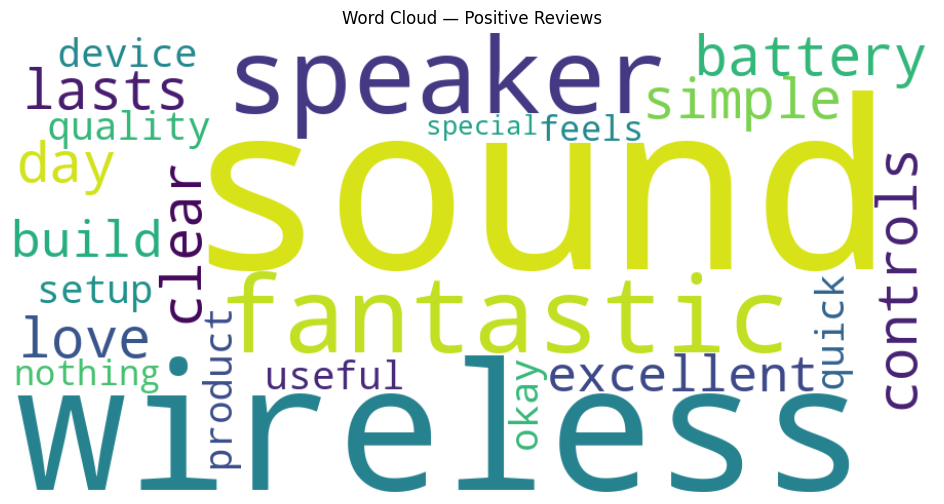


Interpretation:
Polarity ranges from -1 (negative) to +1 (positive). Subjectivity ranges from 0 (more objective) to 1 (more subjective).
The thresholds used here are a simple rule for this assignment; sentiment tools can misclassify context or sarcasm.


In [ ]:
reviews = [
    "This wireless speaker sounds fantastic and the battery lasts all day.",
    "I love the clear sound, simple controls, and excellent build quality.",
    "The product is useful and setup was quick.",
    "The speaker stopped working after two days and customer support was unhelpful.",
    "Very disappointing quality; the connection keeps dropping.",
    "The device is okay, but nothing about it feels special."
]

def sentiment_label(polarity):
    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    return "Neutral"

review_results = []
for i, review in enumerate(reviews, 1):
    blob = TextBlob(review)
    polarity = float(blob.sentiment.polarity)
    subjectivity = float(blob.sentiment.subjectivity)
    label = sentiment_label(polarity)
    review_results.append((review, polarity, subjectivity, label))
    print(f"Review {i}: {review}")
    print(f"  Polarity: {polarity:.3f} | Subjectivity: {subjectivity:.3f} | Class: {label}")

positive_text = " ".join(review for review, polarity, subjectivity, label in review_results if label == "Positive")
if positive_text.strip():
    wc = WordCloud(width=900, height=450, background_color="white", collocations=False).generate(positive_text)
    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud — Positive Reviews")
    plt.show()
else:
    print("No positive reviews were classified; no word cloud generated.")

print("\nInterpretation:")
print("Polarity ranges from -1 (negative) to +1 (positive). Subjectivity ranges from 0 (more objective) to 1 (more subjective).")
print("The thresholds used here are a simple rule for this assignment; sentiment tools can misclassify context or sarcasm.")

In [ ]:
training_text = (
    "Technology can help people learn new skills and solve practical problems. "
    "A curious student asks questions, tests ideas, and learns from mistakes. "
    "Artificial intelligence can organize information and recognize patterns in data. "
    "People should use technology thoughtfully, protect privacy, and check important facts. "
    "Learning improves when practice is regular and goals are clear. "
    "Creative thinking connects knowledge with real world needs. "
    "In the future, responsible innovation can support education, science, and healthcare. "
    "Good tools are most useful when people understand their strengths and limitations."
)

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1
sequences = []
for line in training_text.split("."):
    line = line.strip()
    if not line:
        continue
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(token_list) + 1):
        sequences.append(token_list[:i])

max_seq_len = max(len(seq) for seq in sequences)
sequences = pad_sequences(sequences, maxlen=max_seq_len, padding="pre")
X = sequences[:, :-1]
y = sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Vocabulary size:", total_words)
print("Training sequences:", X.shape[0])
print("Input shape:", X.shape, "| Target shape:", y.shape)

tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(total_words, 32, input_length=X.shape[1]),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(total_words, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

history = model.fit(X, y, epochs=100, verbose=0)
print("\nFinal training loss:", round(float(history.history["loss"][-1]), 4))
print("Final training accuracy:", round(float(history.history["accuracy"][-1]), 4))

Vocabulary size: 71
Training sequences: 76
Input shape: (76, 11) | Target shape: (76, 71)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Final training loss: 1.4524
Final training accuracy: 0.7632


In [ ]:
def generate_text(seed_text, next_words=25):
    output_text = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([output_text])[0]
        token_list = pad_sequences([token_list], maxlen=X.shape[1], padding="pre")
        probabilities = model.predict(token_list, verbose=0)[0]
        # Choose the most probable next word for reproducible, simple demonstration.
        predicted_id = int(np.argmax(probabilities))
        predicted_word = next((word for word, idx in tokenizer.word_index.items() if idx == predicted_id), "")
        if not predicted_word:
            break
        output_text += " " + predicted_word
    return output_text

for seed in ["technology", "learning", "artificial intelligence"]:
    print(f"Seed: {seed}\nGenerated: {generate_text(seed, next_words=12)}\n")

Seed: technology
Generated: technology use use use protect protect privacy and check important facts problems problems

Seed: learning
Generated: learning improves improves practice is and and goals are clear healthcare problems problems

Seed: artificial intelligence
Generated: artificial intelligence can can information and and patterns in data problems problems problems problems

